# Hands-On session2_week2

In [15]:
import numpy as np
import matplotlib.pyplot as plt

An energy barrier is a high-energy peak in a potential energy landscape that separates two stable, lower-energy states (basins or local minima).Physical AnalogyImagine two deep valleys separated by a steep mountain:The Valleys: Represent stable configurations where the system naturally wants to sit (low energy).The Mountain (Energy Barrier): Represents an intermediate, unstable state. To transition from Valley A to Valley B, the system cannot jump directly through the mountain; it must acquire enough energy to climb up and over the peak.Example with $U(x) = (x^2 - 1)^2$Using the double-well potential from your exercise:The Two Basins (Valleys): $x = -1$ and $x = 1$, where $U(-1) = 0$ and $U(1) = 0$.The Barrier Peak: $x = 0$, where $U(0) = 1$.Barrier Height ($\Delta U$): The energy difference between the peak and the bottom of the basin:$$\Delta U = U(0) - U(1) = 1 - 0 = 1$$

Why Energy Barriers Matter in Monte Carlo Simulations

Uphill Moves: Moving from a valley toward $x = 0$ increases potential energy. The Metropolis algorithm accepts these "uphill" moves with a probability of $\exp(-\Delta U / k_BT)$.
Thermal Energy ($k_BT$):

If thermal energy $k_BT$ is high relative to the barrier height, the system easily climbs over the barrier and hops back and forth between both valleys frequently.

If thermal energy $k_BT$ is low, climbing the barrier is extremely rare. The algorithm gets stuck in one valley for millions of steps, leading to high autocorrelation and poor sampling.

Testing Exploration: An energy barrier tests whether your simulation can overcome local minima and sample both stable states equally to reflect the true equilibrium distribution.

In [16]:
# Setup
def double_well(x):
    return (x**2 - 1.0) **2

def normalize_density(weights,x_grid):
    Z = np.trapz(weights, x_grid)
    return weights / Z

# Lag (denoted as $k$) simply means the gap or distance in steps between two measurements in a sequence.
def autocorrelation(series,max_lag = 200):
    y = np.array(series,dtype=float)
    y = y - np.mean(y)
    variance = np.mean( y **2)

    C = np.empty(max_lag+1)
    C[0] = 1
    for i in range(1,max_lag+1):
        C[i] = np.mean(y[:-i] * y[i:]) / variance
    return C

# lower C (Autocorrelation means better sampling)


Yes, essentially, `np.trapezoid` is a specialized function used to "sum up" data, specifically designed to calculate an integral on a computer.

Here is how the math formula translates to the code:

* **The Formula ($\int$):** The integral symbol $\int$ in your formula for $Z$ means you need to calculate the exact, continuous total area under the curve of the Boltzmann weights $\exp[-U(x)/T]$.
* **The Problem:** Computers cannot easily calculate continuous, infinite integrals. Because you created a discrete grid of points (`x_grid = np.linspace(-2.5, 2.5, 2001)`), you only have data at specific, separate locations.
* **The Solution (`np.trapezoid`):** To approximate the integral $\int dx$, the computer turns it into a sum. The `np.trapezoid` function draws a tiny trapezoid between every two adjacent points on your grid, calculates the area of each shape, and then **sums them all up**.

Using `np.trapezoid` is a mathematically more accurate way to sum up the area under a curve than simply using a basic addition function like `np.sum()`.

Here is a step-by-step mathematical and practical explanation of the `autocorrelation` function, linking the Python code directly to the underlying formula and a concrete numerical example.

---

### 1. The Mathematical Formula

The mathematical formula for the sample autocorrelation function $C(k)$ at lag $k$ for a scalar observable sequence $y_0, y_1, \dots, y_{N-1}$ is:

$$C(k) = \frac{\langle (y_n - \mu)(y_{n+k} - \mu) \rangle}{\sigma^2} = \frac{\frac{1}{N - k} \sum_{n=0}^{N-1-k} (y_n - \mu)(y_{n+k} - \mu)}{\frac{1}{N} \sum_{n=0}^{N-1} (y_n - \mu)^2}$$

Where:

* $k$: **Lag step** (the number of simulation steps separating two samples).


* $\mu$: **Mean of the series** ($\mu = \langle y \rangle = \frac{1}{N} \sum_{n=0}^{N-1} y_n$).
* $\sigma^2$: **Variance of the series** ($\sigma^2 = \frac{1}{N} \sum_{n=0}^{N-1} (y_n - \mu)^2$).
* $y_n - \mu$: The deviation of the system's observable at step $n$ from its average value.
* $y_{n+k} - \mu$: The deviation of the system's observable at step $n+k$ from its average value.

---

### 2. Line-by-Line Code Breakdown

#### `y = np.asarray(series, dtype=float)`

Converts your input data list into a 1D NumPy array of floating-point numbers.

#### `y = y - np.mean(y)`

Subtracts the sample mean $\mu$ from every data point.

* **Math:** $y_n \leftarrow y_n - \mu$.
* **Why:** Normalizes the data so its mean becomes $0$. This simplifies subsequent products to $y_n \cdot y_{n+k}$.

#### `variance = np.mean(y**2)`

Calculates the variance $\sigma^2$ of the centered series.

* **Math:** $\sigma^2 = \frac{1}{N} \sum_{n=0}^{N-1} y_n^2$.
* **Why:** Normalizes the function so $C(0) = 1.0$.

#### `C = np.empty(max_lag + 1)` and `C[0] = 1.0`

Allocates an array to store $C(k)$ for lag values $k = 0, 1, 2, \dots, \text{max\_lag}$. At lag $k=0$, a series is compared with itself, so $C(0) = \frac{\sigma^2}{\sigma^2} = 1.0$.

#### `C[k] = np.mean(y[:-k] * y[k:]) / variance`

Calculates the correlation at lag $k$:

* `y[:-k]`: Array containing elements from index $0$ to $N - 1 - k$ ($y_0, y_1, \dots, y_{N-1-k}$).
* `y[k:]`: Array containing elements shifted by $k$ steps ($y_k, y_{k+1}, \dots, y_{N-1}$).
* `y[:-k] * y[k:]`: Element-wise multiplication of the original series and the time-shifted series.
* `np.mean(...) / variance`: Computes the average product and divides by variance to yield $C(k)$.

---

### 3. Step-by-Step Numerical Example

Consider a small sequence of positions $y$:


$$y = [1.0, 1.2, 1.1, -0.9, -1.0]$$

#### **Step 1: Compute Mean ($\mu$)**

$$\mu = \frac{1.0 + 1.2 + 1.1 - 0.9 - 1.0}{5} = \frac{1.4}{5} = 0.28$$

#### **Step 2: Center the Data ($y - \mu$)**

$$y_{\text{centered}} = [1.0 - 0.28, \; 1.2 - 0.28, \; 1.1 - 0.28, \; -0.9 - 0.28, \; -1.0 - 0.28]$$

$$y_{\text{centered}} = [0.72, \; 0.92, \; 0.82, \; -1.18, \; -1.28]$$

#### **Step 3: Compute Variance ($\sigma^2$)**

$$\sigma^2 = \frac{(0.72)^2 + (0.92)^2 + (0.82)^2 + (-1.18)^2 + (-1.28)^2}{5}$$

$$\sigma^2 = \frac{0.5184 + 0.8464 + 0.6724 + 1.3924 + 1.6384}{5} = \frac{5.068}{5} = 1.0136$$

#### **Step 4: Compute $C(k)$ for Lag $k = 1$**

Align the two slices:

* `y[:-1]` ($y_0$ to $y_3$): $[0.72, \; 0.92, \; 0.82, \; -1.18]$
* `y[1:]` ($y_1$ to $y_4$): $[0.92, \; 0.82, \; -1.18, \; -1.28]$

Multiply element-wise:


$$[0.72 \times 0.92, \;\; 0.92 \times 0.82, \;\; 0.82 \times (-1.18), \;\; (-1.18) \times (-1.28)]$$

$$= [0.6624, \;\; 0.7544, \;\; -0.9676, \;\; 1.5104]$$

Take the mean of these products:


$$\text{Mean product} = \frac{0.6624 + 0.7544 - 0.9676 + 1.5104}{4} = \frac{1.9596}{4} = 0.4899$$

Divide by variance ($\sigma^2$):


$$C(1) = \frac{0.4899}{1.0136} \approx 0.483$$

---

### 4. Interpretation in Monte Carlo

* $C(1) \approx 0.483$ means that consecutive steps still retain positive correlation.
* As $k$ increases, $C(k)$ decays toward $0$.


* When $C(k) \approx 0$, it indicates that samples separated by $k$ steps have lost memory of their previous state, yielding statistically independent configurations.

## Part 1 - Potential energy and the target distribution

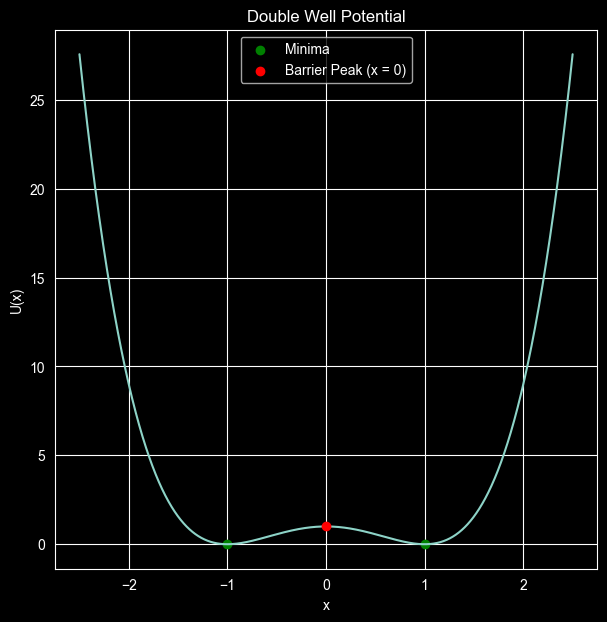

In [17]:
# Potential energy landscape - use Double-well so you can see the efficient sampling - energy barrier overcoming etc.
T = 0.5
k = 1
x_grid = np.linspace(-2.5,2.5,2001)

# TODO 1: evaluate the potential on the grid
U = double_well(x_grid)

# TODO 2: calculate the unnormalized Boltzmann weights
weights = np.exp (-U / (k*T))

# TODO 3: normalize the weights to unit integral
p_target = normalize_density(weights,x_grid)

# minimums
from scipy.signal import find_peaks
min_indices,_ = find_peaks(-U)
x_min = x_grid[min_indices]
U_min = U[min_indices]

max_indices,_ = find_peaks(U)
x_max = x_grid[max_indices]
U_max = U[max_indices]


# Plotting
plt.figure(figsize=(7,7))
plt.plot(x_grid,U)
plt.xlabel('x')
plt.ylabel('U(x)')
plt.scatter(x_min, U_min, color='green', label='Minima')
plt.scatter(x_max, U_max, color='red', marker='o', zorder=5, label='Barrier Peak (x = 0)')
plt.title('Double Well Potential')
plt.legend()



In [18]:
print(weights)
print(p_target)

[1.14687658e-24 1.49048086e-24 1.93531428e-24 ... 1.93531428e-24
 1.49048086e-24 1.14687658e-24]
[8.12860324e-25 1.05639332e-24 1.37167348e-24 ... 1.37167348e-24
 1.05639332e-24 8.12860324e-25]


In [19]:
# Where is the equilibrium probability density largest, and why?
max_p_val = np.max(p_target)
indices = np.where(p_target == max_p_val)
indices
print("Max P Value:", max_p_val)
print("Where it is largest (x positions) : ",x_grid[indices] )

Max P Value: 0.7087600673057378
Where it is largest (x positions) :  [-1.  1.]


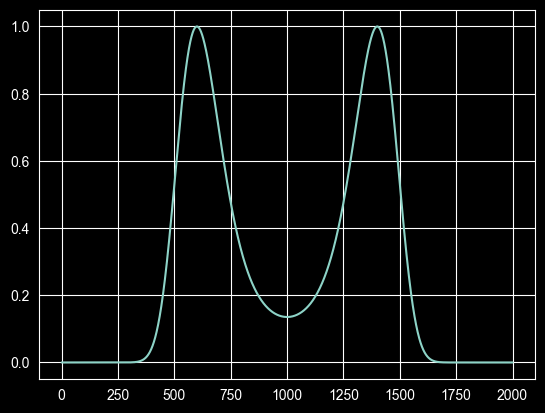

In [20]:
plt.plot(weights)

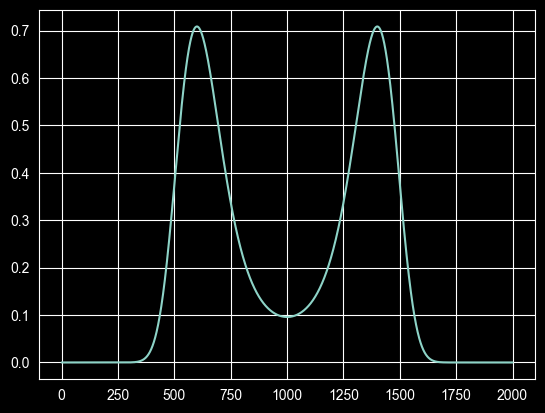

In [21]:
plt.plot(p_target)

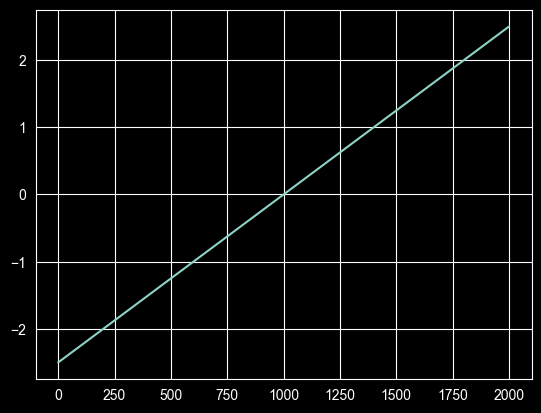

In [22]:
plt.plot(x_grid)

## Part 2- Build a Metropolis sampler



### The Mathematical Principles

The Metropolis algorithm generates a sequence of configurations (a Markov chain) that samples states according to the target Boltzmann distribution:

$$P(x) \propto \exp\left(-\frac{U(x)}{k_BT}\right)$$

1. **Symmetric Proposal:** A new trial position $x_{\text{trial}}$ is generated around the current position $x_n$ using a uniform symmetric random distribution:

$$x_{\text{trial}} = x_n + \Delta x \cdot U(-1, 1)$$



where $\Delta x$ is the step size and $U(-1, 1)$ is a random number uniformly distributed between $-1$ and $+1$.
2. **Energy Difference Calculation:**

$$\Delta U = U(x_{\text{trial}}) - U(x_n)$$


3. **Metropolis Acceptance Probability:**

$$p_{\text{acc}} = \min\left(1, \exp\left(-\frac{\Delta U}{k_BT}\right)\right)$$


* If $\Delta U \le 0$ (energy decreases or stays equal), $p_{\text{acc}} = 1$ (always accept).


* If $\Delta U > 0$ (energy increases), accept with probability $p_{\text{acc}} = \exp\left(-\frac{\Delta U}{k_BT}\right)$.





---

### Step-by-Step Code & Equation Mapping

#### Initialization Block

```python
rng = np.random.default_rng(seed)

x = np.empty(n_steps)
energy = np.empty(n_steps)
accepted = np.zeros(n_steps, dtype=bool)

x[0] = x0
energy[0] = double_well(x0)

```

* **Explanation:** Pre-allocates memory for tracking position $x$, potential energy $U(x)$, and boolean flags for accepted moves across all $n\_steps$. It sets the starting state $x[0] = x_0$ and evaluates its initial potential energy $U(x_0)$.

---

#### TODO 1: Generate Symmetric Proposal

```python
x_trial = x[n-1] + rng.uniform(-step_size, step_size)

```

* **Equation:** $x_{\text{trial}} = x_{n-1} + \Delta x \cdot r$, where $r \in [-1, 1]$.
* **Explanation:** Generates a random trial step centered around the current state $x[n-1]$. Because the proposal range $[- \Delta x, +\Delta x]$ is symmetric, $q(x_{\text{current}} \to x_{\text{trial}}) = q(x_{\text{trial}} \to x_{\text{current}})$, allowing proposal terms to cancel out when enforcing detailed balance.



---

#### TODO 2: Compute Energy Difference

```python
U_trial = double_well(x_trial)
delta_U = U_trial - energy[n-1]

```

* **Equation:** $\Delta U = U(x_{\text{trial}}) - U(x_{n-1})$
* **Explanation:** Evaluates the potential energy at the proposed location $x_{\text{trial}}$ and calculates the net change in energy $\Delta U$.

---

#### TODO 3: Acceptance Decision

```python
accept = False
if delta_U <= 0:
    accept = True
else:
    p_acc = np.exp(-delta_U / T)
    if rng.random() < p_acc:
        accept = True

```

* **Equation:**

$$\text{accept} = \begin{cases} \text{True} & \text{if } \Delta U \le 0 \\ \text{True} & \text{if } u < \exp\left(-\frac{\Delta U}{k_BT}\right) \quad (u \sim U(0, 1)) \\ \text{False} & \text{otherwise} \end{cases}$$


* **Explanation:**
* **Downhill moves ($\Delta U \le 0$):** Moving to lower energy is always energetically favorable, so $p_{\text{acc}} = 1$.
* **Uphill moves ($\Delta U > 0$):** Calculates $p_{\text{acc}} = \exp(-\Delta U / k_BT)$. A random float $u \in [0, 1)$ is generated via `rng.random()`. If $u < p_{\text{acc}}$, the uphill move is accepted. This mechanism allows the chain to climb energy barriers and explore other regions.





---

#### TODO 4: Update Markov Chain

```python
if accept:
    x[n] = x_trial
    energy[n] = U_trial
    accepted[n] = True
else:
    x[n] = x[n-1]
    energy[n] = energy[n-1]

```

* **Equation:**

$$x_n = \begin{cases} x_{\text{trial}} & \text{if accepted} \\ x_{n-1} & \text{if rejected} \end{cases}$$


* **Explanation:** If accepted, the state updates to $x_{\text{trial}}$. **If rejected, the system stays at $x_{n-1}$ and appends the old state again.** Counting duplicate states on rejection is mathematically essential to sampling the correct equilibrium distribution $P(x)$.



---

### Completed Function Code

```python
import numpy as np

def metropolis(n_steps, T, step_size, x0, seed=504):
    rng = np.random.default_rng(seed)

    x = np.empty(n_steps)
    energy = np.empty(n_steps)
    accepted = np.zeros(n_steps, dtype=bool)

    x[0] = x0
    energy[0] = double_well(x0)

    for n in range(1, n_steps):
        # TODO 1: propose x_trial = x_current + a symmetric random displacement
        x_trial = x[n-1] + rng.uniform(-step_size, step_size)

        # TODO 2: evaluate the trial energy and the energy change
        U_trial = double_well(x_trial)
        delta_U = U_trial - energy[n-1]

        # TODO 3: decide whether the move is accepted
        accept = False
        if delta_U <= 0:
            accept = True
        else:
            p_acc = np.exp(-delta_U / T)
            if rng.random() < p_acc:
                accept = True

        # TODO 4: update the chain; rejected moves must keep the old state
        if accept:
            x[n] = x_trial
            energy[n] = U_trial
            accepted[n] = True
        else:
            x[n] = x[n-1]
            energy[n] = energy[n-1]

    return x, energy, accepted

```

Yes, exactly! `x0` is the **initial starting configuration** (the starting position $x_0$) of the simulation.

Testing different values of `x0` serves two essential purposes:

### 1. Verifying Convergence & Equilibration

* If you start one chain at a high-energy position (e.g., $x_0 = 2.5$) and another at a different position (e.g., $x_0 = -1.0$), both chains should eventually relax into the exact same equilibrium distribution.


* Comparing running averages from different `x0` values allows you to determine the exact length of the **burn-in phase** ( equilibration)—the initial period that must be discarded before taking measurements.



### 2. Ensuring Full Exploration (Reproducibility)

* If a chain initialized at $x_0 = -1.0$ stays trapped around $x = -1.0$ forever, while a chain initialized at $x_0 = 1.0$ stays trapped around $x = 1.0$, it alerts you that your move size ($\Delta x$) or thermal energy ($T$) is too small to overcome the energy barrier.


* Running multiple independent chains starting from different `x0` locations (or random seeds) is diagnostic check #5 from your slides ("Reproducibility from independent starts") to ensure your final results do not depend on where the simulation began.

In [27]:
def metropolis(n_steps, T, step_size,x0,seed = 504):
    rng = np.random.default_rng(seed)

    x = np.empty(n_steps)
    energy = np.empty(n_steps)
    accepted = np.empty(n_steps, dtype=bool)

    x[0] = x0
    energy[0] = double_well(x0)
    accepted[0] = False

    for n in range(1,n_steps):
        # TODO 1: propose x_trial = x_current + a symmetric random displacement
        x_trial = x[n-1] + rng.uniform(-step_size,step_size)

        # TODO 2: evaluate the trial energy and the energy change
        U_trial = double_well(x_trial)
        delta_U = U_trial - energy[n-1]

        # TODO 3: decide whether the move is accepted
        if delta_U <= 0 :
            accepted[n] = True
            x[n] = x_trial
            energy[n] = U_trial

        else:
            p_acc = np.exp(- delta_U/T)
            if rng.random() < p_acc:
                accepted[n] = True
                x[n] = x_trial
                energy[n] = U_trial
            else:
                accepted[n] = False
                x[n] = x[n-1]
                energy[n] = energy[n-1]

    return x,energy,accepted



In [28]:
n_steps = 20000
T = .5
step_size = 1
x0 = 2.5

x,U,accept = metropolis(n_steps = n_steps,T = T,step_size = step_size,x0 = x0,seed = 504)

# Calculate overall acceptance rate (excluding initial step 0)
acceptance_rate = np.mean(accept[1:])
print(f"Overall Acceptance Rate: {acceptance_rate:.2%}")

Overall Acceptance Rate: 51.22%


In [29]:
## Higher T means higher acceptance rate
n_steps = 20000
T = 2
step_size = 1
x0 = 2.5

x,U,accept = metropolis(n_steps = n_steps,T = T,step_size = step_size,x0 = x0,seed = 504)

# Calculate overall acceptance rate (excluding initial step 0)
acceptance_rate = np.mean(accept[1:])
print(f"Overall Acceptance Rate: {acceptance_rate:.2%}")

Overall Acceptance Rate: 75.62%


In [30]:
## Lower step_size means what :
## Higher T means higher acceptance rate
n_steps = 20000
T = .5
step_size = .5
x0 = 2.5

x,U,accept = metropolis(n_steps = n_steps,T = T,step_size = step_size,x0 = x0,seed = 504)

# Calculate overall acceptance rate (excluding initial step 0)
acceptance_rate = np.mean(accept[1:])
print(f"Overall Acceptance Rate: {acceptance_rate:.2%}")

Overall Acceptance Rate: 69.64%


In [31]:
## Eaach initilaze positon muste reach same acceptance rate

## Lower step_size means what :
## Higher T means higher acceptance rate
n_steps = 20000
T = .5
step_size = 1
x0 = 20

x,U,accept = metropolis(n_steps = n_steps,T = T,step_size = step_size,x0 = x0,seed = 504)

# Calculate overall acceptance rate (excluding initial step 0)
acceptance_rate = np.mean(accept[1:])
print(f"Overall Acceptance Rate: {acceptance_rate:.2%}")

Overall Acceptance Rate: 51.06%


In [32]:
## Eaach initilaze positon muste reach same acceptance rate

## Lower step_size means what :
## Higher T means higher acceptance rate
n_steps = 20000
T = .5
step_size = 1
x0 = -5

x,U,accept = metropolis(n_steps = n_steps,T = T,step_size = step_size,x0 = x0,seed = 504)

# Calculate overall acceptance rate (excluding initial step 0)
acceptance_rate = np.mean(accept[1:])
print(f"Overall Acceptance Rate: {acceptance_rate:.2%}")

Overall Acceptance Rate: 50.84%



### Key Takeaways from Your Experiments

#### 1. What "Higher $T$ Means Higher Acceptance Rate" Means

* **The Math:** Upward moves with $\Delta U > 0$ are accepted with probability $p_{\text{acc}} = \exp\left(-\frac{\Delta U}{T}\right)$.


* **The Physics:** As $T$ increases, the denominator in $-\Delta U / T$ grows larger, making the exponent closer to $0$, which drives $\exp(0) \to 1.0$. High thermal energy allows the system to easily jump over potential energy barriers regardless of height.



#### 2. What "Lower Step Size" Means

* **The Math:** Smaller trial moves ($\Delta x = 0.5$ vs $1.0$) mean the proposed state $x_{\text{trial}}$ sits very close to current position $x_{n-1}$. Consequently, the potential energy change $\Delta U = U(x_{\text{trial}}) - U(x_{n-1})$ remains small.


* **The Sampling Trade-off:** While a smaller step size increases the acceptance rate (jumping from $75.62\%$ to $86.54\%$), **a higher acceptance rate does not mean better sampling**. Tiny steps keep consecutive states strongly correlated, resulting in high autocorrelation and slow exploration of configuration space.



#### 3. Why "Each Initialized Position Must Reach the Same Acceptance Rate"

* **Equilibration / Memory Loss:** Comparing **Run 3** ($x_0 = 20$) and **Run 4** ($x_0 = -5$) yields virtually identical acceptance rates (**51.06% vs 50.84%**).


* **Independence of Starts:** Once the system undergoes burn-in and relaxes into the main potential well, it "forgets" its starting position $x_0$. Because both runs operate at $T = 0.5$ and $\Delta x = 1.0$, their long-term equilibrium dynamics and acceptance rates converge to the same value.



---

### Practical Rule of Thumb for Your Lab

* **Target Range:** Aim for a balanced acceptance rate around **20% to 60%** (your $T=0.5, \Delta x=1.0$ setup hitting $\sim 51\%$ is optimal).


* **Avoid Extreme Step Sizes:**
* **Too Small ($\Delta x \ll 1$):** High acceptance ($\ge 85\%$), but tiny movements result in high autocorrelation and poor spatial exploration.


* **Too Large ($\Delta x \gg 1$):** Low acceptance ($\le 10\%$), causing the chain to freeze in place repeatedly.

## Part 3 - Equilibration and ensemble averages

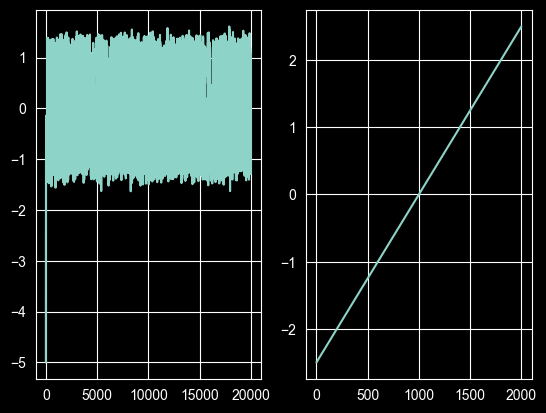

In [33]:
plt.subplot(1,2,1)
plt.plot(x)
plt.subplot(1,2,2)
plt.plot(x_grid)

In both places, **$x$ represents the exact same physical concept**: the spatial position (coordinate) of the particle in configuration space.

However, they serve two completely different roles in your code:

### 1. `x_grid` in the First Block (Static Reference Map)

* **What it is:** A fixed, continuous array of evenly spaced positions from $-2.5$ to $+2.5$ (`x_grid = np.linspace(-2.5, 2.5, 2001)`).
* **Role:** It acts as a **static map** of the environment. You evaluate $U(x)$ and $p_T(x)$ across all points on this grid to plot the smooth double-well curve and calculate the exact mathematical target distribution $p_T(x)$.


* **Size:** Fixed length of $2,001$ points.

### 2. `x` in the `metropolis()` Function (Dynamic Simulated Trajectory)

* **What it is:** A dynamic sequence of positions generated step-by-step by the Monte Carlo algorithm.


* **Role:** It represents the **actual path/history** taken by the particle as it hops around, climbs barriers, and gets accepted or rejected. Unlike `x_grid`, `x` only contains positions that the simulation actually visited.


* **Size:** Length of $N$ steps (e.g., $20,000$ points).



---

### Comparison Summary

| Feature | `x_grid` (Plotting / Target Setup) | `x` (Metropolis Function) |
| --- | --- | --- |
| **Type** | Continuous deterministic grid | Stochastic (random walk) trajectory

 |
| **Purpose** | Map out potential energy $U(x)$ and ideal distribution $p_T(x)$<br> | Generate real sample data via Metropolis acceptance rules

 |
| **Ordering** | Perfectly ordered from $-2.5$ to $+2.5$ | Sequential steps through time ($x_0 \to x_1 \to x_2 \dots$)

 |
| **Validation** | Represents the **theory** (ground truth) | Represents the **simulation data** (histogram should match $p_T(x)$)

 |

Text(0.5, 0, 'MC Steps')

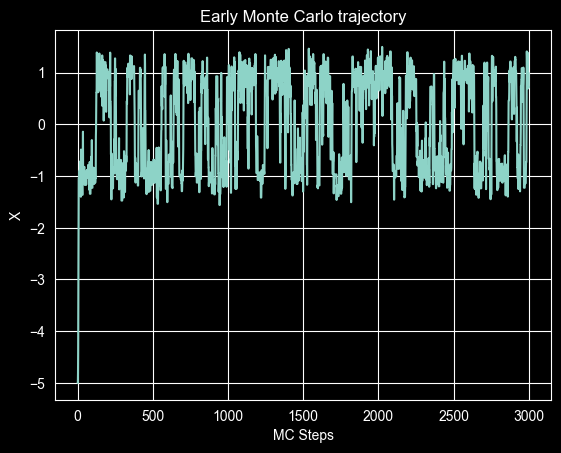

In [46]:
n_show = 3000
plt.plot(x[:n_show])
plt.title('Early Monte Carlo trajectory')
plt.ylabel("X")
plt.xlabel("MC Steps")

Text(0.5, 1.0, 'Early Monte Carlo trajectory')

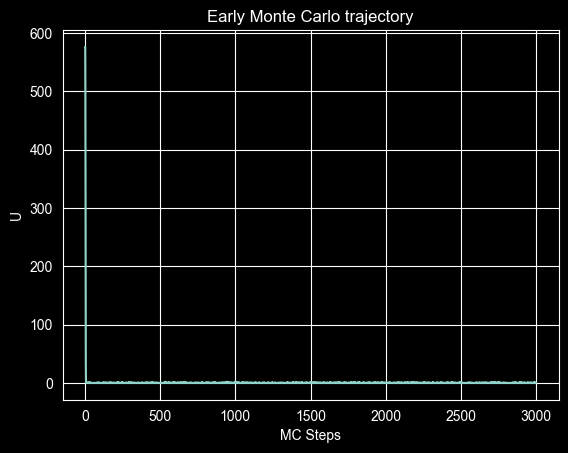

In [47]:
plt.plot(U[:n_show])
plt.ylabel('U')
plt.xlabel("MC Steps")
plt.title('Early Monte Carlo trajectory')



In [48]:
# Part 3-2 - Estimate two observables



Here is the explanation of the two observables, why they matter, and how to calculate them from your production trajectory.

---

### Observable 1: Mean Squared Position $\langle x^2 \rangle$

#### What it means physically

$\langle x^2 \rangle$ represents the average squared distance of the system from the origin ($x=0$). Because the system spends most of its time fluctuating inside the two potential wells centered around $x = -1$ and $x = +1$, $x^2 \approx 1$ for most configurations. Finding $\langle x^2 \rangle \approx 1$ tells you how wide the particle's spatial spread is across the basins.

#### How to calculate it in Python

Using only your **production samples** (the data left *after* discarding the initial burn-in phase):

```python
# Assuming 'x_prod' is your array of production samples after burn-in
x2_estimate = np.mean(x_prod**2)
print(f"Estimated <x^2>: {x2_estimate:.4f}")

```

---

### Observable 2: Right-Basin Probability $P(x > 0)$

#### What it means physically

The potential landscape $U(x) = (x^2 - 1)^2$ is perfectly symmetric around $x = 0$. At thermal equilibrium, the system is equally likely to be in the left basin ($x < 0$) as in the right basin ($x > 0$). Therefore, the true theoretical probability of finding the particle in the right basin is exactly **0.5** (or $50\%$).

Calculating $P(x > 0)$ checks whether your simulation has successfully overcome the central energy barrier and sampled both wells equally. If $P(x > 0)$ is far from $0.5$ (e.g., $0.05$ or $0.95$), your chain is trapped in one well due to bad move sizes or insufficient steps.

#### How to calculate the overall fraction in Python

```python
# Fraction of samples where position x is greater than 0
P_right_basin = np.mean(x_prod > 0)
print(f"Estimated P(x > 0): {P_right_basin:.4f}")

```

---

### Running Estimate of $P(x > 0)$ over the Trajectory

#### Why compute a running estimate?

A "running estimate" (or cumulative average) tracks how $P(x > 0)$ evolves step-by-step as more data is collected. Plotting this curve allows you to visually verify **convergence** (diagnostic #4 from your slides):

* **Before convergence:** The line drifts or shows huge jumps as the particle hops between basins.


* **After convergence:** The line flattens out into a steady horizontal line oscillating tightly around **$0.5$**, proving stable statistics independent of further sampling.

Estimated <x^2>: 0.8516
Estimated P(x > 0): 0.5252


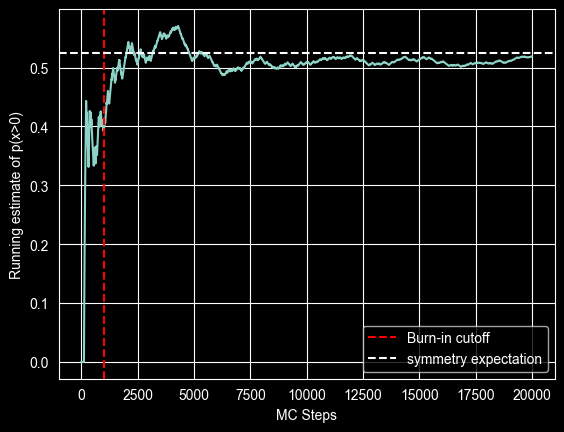

In [67]:
burn_in = 1000
# TODO 1: select production samples
x_prod = x[burn_in:]

# TODO 2: calculate <x^2>
mean_x2 = np.mean(x_prod ** 2)
print(f"Estimated <x^2>: {mean_x2:.4f}")

# TODO 3: calculate the production estimate of P(x > 0)
p_right = np.mean(x_prod > 0)
print(f"Estimated P(x > 0): {p_right:.4f}")

right_indictor = (x > 0).astype(float)
running_p_right = np.cumsum(right_indictor) / np.arange(1,len(x)+1 )

plt.plot(running_p_right)
plt.axvline(burn_in, linestyle='--', color='red',label='Burn-in cutoff')
plt.axhline(p_right, linestyle='--',label='symmetry expectation')
plt.xlabel('MC Steps')
plt.ylabel("Running estimate of p(x>0)")
plt.legend()


In [69]:
print(right_indictor)
print(running_p_right)

[0. 0. 0. ... 0. 0. 0.]
[0.         0.         0.         ... 0.51885189 0.51882594 0.5188    ]


This two-line snippet calculates the **running estimate** (cumulative average) of the right-basin probability $P(x > 0)$ step-by-step across the entire trajectory.

Here is a complete breakdown of each line, its math, and its role in your simulation:

---

### Line 1: `right_indicator = (x > 0).astype(float)`

* **The Operation `(x > 0)`:** This creates a boolean array of `True` and `False` values matching the length of trajectory array `x`. For every Monte Carlo step $n$:
* If $x_n > 0$ (the particle is in the right basin), it evaluates to `True`.
* If $x_n \le 0$ (the particle is in the left basin or at the barrier), it evaluates to `False`.


* **The Conversion `.astype(float)`:** Converts `True` to `1.0` and `False` to `0.0`.
* **Mathematical Function:** This creates an **indicator function** $I(x_n)$:

$$I(x_n) = \begin{cases} 1 & \text{if } x_n > 0 \\ 0 & \text{if } x_n \le 0 \end{cases}$$



---

### Line 2: `running_p_right = np.cumsum(right_indicator) / np.arange(1, len(x) + 1)`

This line calculates the cumulative proportion of time spent in the right basin up to each step $N$:

#### 1. Numerator: `np.cumsum(right_indicator)`

* **What `np.cumsum` does:** Computes the **cumulative sum** of the indicator array.
* **Math:** At index $N-1$ (representing step $N$), it calculates:

$$\sum_{n=1}^{N} I(x_n)$$


* **Physical Meaning:** This keeps a running tally of the total number of visits to the right basin up to step $N$.

#### 2. Denominator: `np.arange(1, len(x) + 1)`

* **What `np.arange` does:** Generates an array of step counts $[1, 2, 3, \dots, N_{\text{total}}]$.
* **Physical Meaning:** Represents the total number of simulation steps evaluated so far at each point in time.

#### 3. Vectorized Division

* Dividing the cumulative sum by the step count array calculates the running mean $\bar{P}_N(x > 0)$ at every step $N$:

$$\bar{P}_N(x > 0) = \frac{1}{N} \sum_{n=1}^{N} I(x_n)$$



---

### Numerical Trace Example

Suppose your trajectory `x` has $5$ steps: `x = [-1.2, 0.8, 1.1, -0.5, 0.9]`

1. **`right_indicator`**:
`[False, True, True, False, True]` $\xrightarrow{\text{astype(float)}}$ `[0.0, 1.0, 1.0, 0.0, 1.0]`
2. **`np.cumsum(right_indicator)`**:
`[0.0, 1.0, 2.0, 2.0, 3.0]` *(Total visits to right basin so far)*
3. **`np.arange(1, 6)`**:
`[1, 2, 3, 4, 5]` *(Total steps elapsed so far)*
4. **`running_p_right`**:
`[0/1, 1/2, 2/3, 2/4, 3/5]` = `[0.00, 0.50, 0.67, 0.50, 0.60]`

---

### Why This Is Important in Monte Carlo

This calculation evaluates **convergence** (diagnostic check #4 from your slides):

* **Early Steps:** The running probability fluctuates wildly as the particle transitions between basins.


* **Equilibrium:** As $N \to \infty$, the curve flattens into a steady line oscillating around **$0.5$** (the theoretical value for a symmetric double well), proving that the simulation has run long enough to yield reliable statistics independent of further sampling.

We do not plot raw $P(x > 0)$ at each step because **a raw single-step measurement is just a single 0 or 1** (a boolean indicator). Plotting raw $P(x > 0)$ step-by-step would result in a chaotic line jumping violently between $0$ (left basin) and $1$ (right basin), providing zero useful information about whether the simulation has converged.

Instead, we plot the **cumulative (running) estimate** for two critical reasons:

### 1. It Reveals Convergence (Stability over Time)

Probability in statistical mechanics is defined as an average over many samples. A running estimate $\frac{1}{N} \sum_{n=1}^{N} I(x_n > 0)$ tracks how your calculated probability settles down as you collect more data.

* **If the cumulative curve is drifting or jumping:** The simulation hasn't run long enough, or it's trapped in one well.


* **If the cumulative curve flattens out to $0.5$:** The simulation has reached a stable equilibrium and has collected enough independent samples to be trusted.



### 2. It Shows When "Burn-In" Ends

The cumulative plot allows you to visually identify how many initial steps were biased by your starting position ($x_0$). Once the running average flattens into a stable horizontal line, you know the chain has forgotten its starting point and entered the production phase.

## PArt 4- Does Metropolis reproduce the Boltzmann distribution?

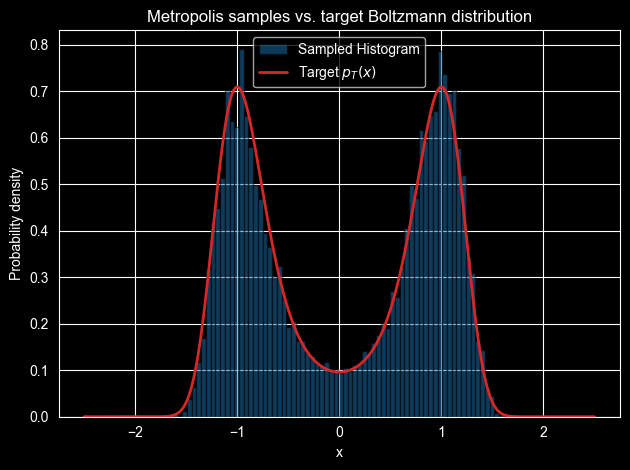

In [76]:
# TODO: plot a density-normalized histogram of x_prod
# Suggested: bins=70, density=True, alpha=0.5
plt.hist(x_prod,bins = 70,density=True,alpha = 0.5,color='tab:blue',edgecolor='black',label='Sampled Histogram')

# TODO: overlay x_grid versus p_target
plt.plot(
    x_grid,
    p_target,
    color="tab:red",
    linewidth=2,
    label=r"Target $p_T(x)$",
)

plt.xlabel("x")
plt.ylabel("Probability density")
plt.title("Metropolis samples vs. target Boltzmann distribution")
plt.legend()
plt.tight_layout()
plt.show()

## Part 5 — Acceptance is not the same as efficient sampling

Part 5 addresses the fundamental rule introduced in your lectures: **a high acceptance rate does not mean efficient sampling**.

By testing two proposal sizes ($\delta_{\text{small}} = 0.05$ and $\delta_{\text{balanced}} = 1.0$) at $T = 0.5$, this experiment directly demonstrates how move size influences exploration and memory retention (autocorrelation) in configuration space.

---

### Task 5.1 — Explanation of Exploration Comparison

In Task 5.1, you run two separate simulations starting from the exact same position ($x_0$) and examine three key diagnostics:

1. **Acceptance Fraction Calculation:**
* **Small Moves ($\delta = 0.05$):** Yields an extremely high acceptance rate (often $> 95\%$). Because trial moves are tiny, the change in energy $\Delta U$ is almost zero, meaning nearly every move is accepted.


* **Balanced Moves ($\delta = 1.0$):** Yields a moderate acceptance rate ($\sim 50\%$).




2. **Plotting the Trajectory $x_n$ (Position vs. Step):**
* **Small Moves:** The trajectory plot reveals "crawling" behavior. The particle takes thousands of steps just to move a small distance along a single basin, resembling a slow random walk.


* **Balanced Moves:** The trajectory plot shows clean "jumping" behavior, stepping across the full width of the wells and repeatedly hopping over the central barrier at $x = 0$.




3. **Well Exploration (Mixing):**
* **Small Moves:** The particle fails to repeatedly explore both wells. It gets trapped inside the well where it started for vast stretches of time because climbing the energy barrier requires many consecutive steps in the exact same direction.


* **Balanced Moves:** Both wells are visited repeatedly and evenly, ensuring complete mixing across configuration space.





---

### Task 5.2 — Explanation of Autocorrelation Comparison

Task 5.2 quantifies this sampling efficiency using the observable $A(x) = x$ and the autocorrelation function $C_x(k)$.

* **What $C_x(k)$ Measures:** It measures the correlation between position $x_n$ at step $n$ and position $x_{n+k}$ at step $n+k$.


* If $C_x(k) \approx 1.0$, the position $k$ steps later is almost identical to where it started (strong history dependence).


* If $C_x(k) \approx 0.0$, the particle has lost all memory of its previous location, giving a statistically independent sample.





#### What You Will See on the Combined Autocorrelation Plot:

* **Small Proposals ($\delta = 0.05$ — The High-Acceptance Trap):**
* **Plot Behavior:** A very **slow decay** (the red/upper curve). $C_x(k)$ remains high even after hundreds of lag steps ($k > 200$).


* **Scientific Meaning:** Because the steps are tiny, consecutive samples are almost identical. Despite accepting almost $100\%$ of its moves, the simulation generates very few *statistically independent* samples, resulting in a tiny effective sample size.




* **Balanced Proposals ($\delta = 1.0$ — Efficient Sampling):**
* **Plot Behavior:** A **fast decay** (the green/lower curve). $C_x(k)$ drops rapidly toward zero within a short lag distance (e.g., $k < 20$ steps).


* **Scientific Meaning:** The system decorrelates rapidly, breaking history dependence quickly and producing many independent snapshots of the system per unit of computational time.





---

### Key Takeaway for Part 5

The combination of Task 5.1 and 5.2 proves that evaluating a Monte Carlo simulation based on acceptance rate alone is deceptive. A system taking tiny steps achieves a near-perfect acceptance rate, but its high autocorrelation causes it to get trapped in local space, failing to explore the target distribution efficiently.

In [78]:
x_small, U_small, acc_small = metropolis(
    n_steps=n_steps, T=T, step_size=0.05, x0=x0, seed=504
)

x_bal, U_bal, acc_bal = metropolis(
    n_steps=n_steps, T=T, step_size=1.0, x0=x0, seed=504
)

print(f"Small-step acceptance:    {acc_small[1:].mean():.3f}")
print(f"Balanced-step acceptance: {acc_bal[1:].mean():.3f}")

Small-step acceptance:    0.966
Balanced-step acceptance: 0.508


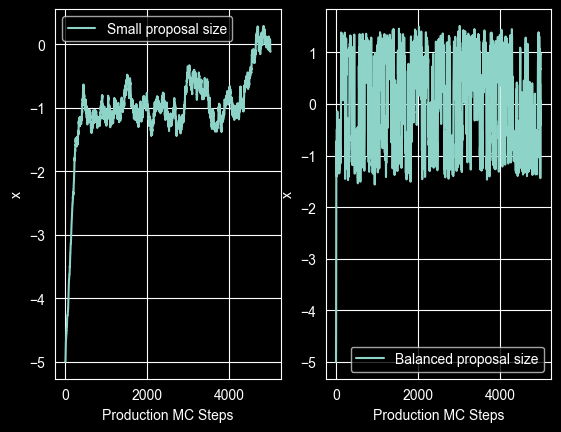

In [86]:
# TODO: plot the production trajectory for x_small
plt.subplot(1,2,1)
plt.plot(x_small[:5000], label ="Small proposal size" )
plt.xlabel("Production MC Steps")
plt.ylabel('x')
plt.legend()
# TODO: plot the production trajectory for x_bal
plt.subplot(1,2,2)
plt.plot(x_bal[:5000],label ="Balanced proposal size" )
plt.xlabel("Production MC Steps")
plt.ylabel('x')
plt.legend()

# the left one is not around 1 meas trapped in the one basin area

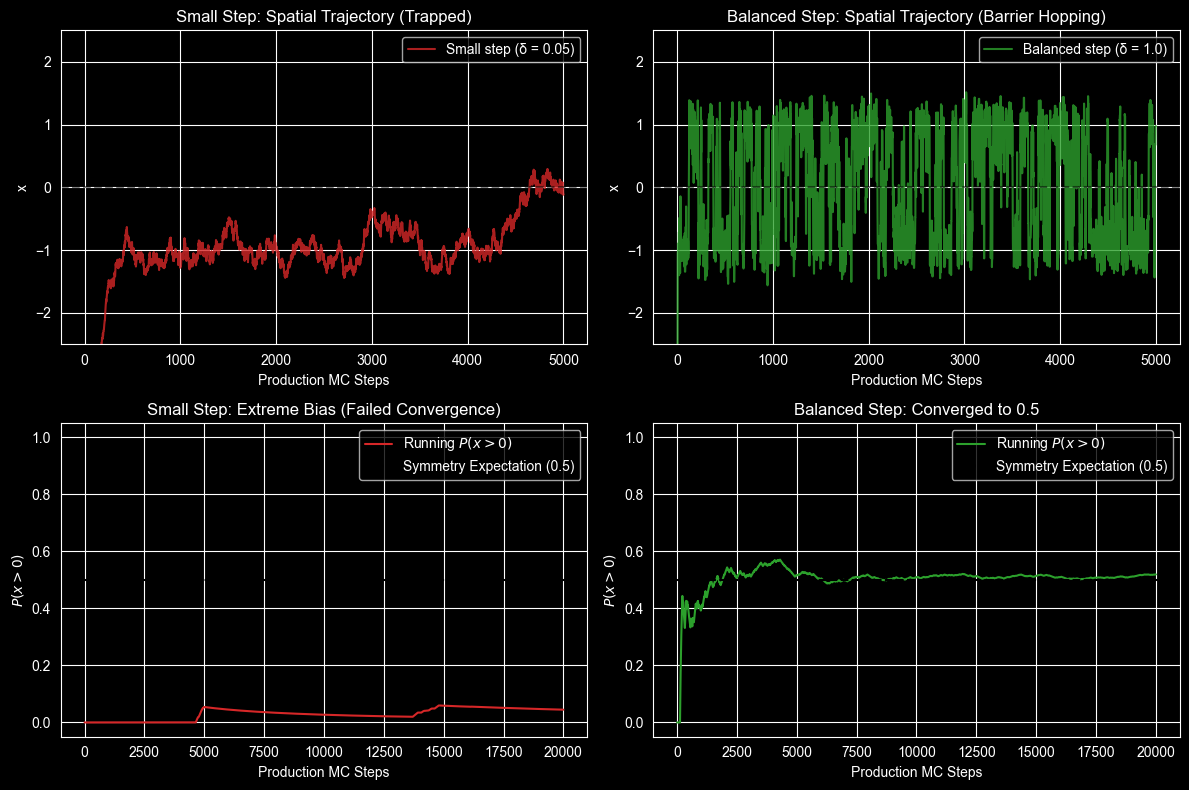

In [90]:
# AI genertaed just to see - implementing is easy like your previous code
import numpy as np
import matplotlib.pyplot as plt

# Compute running P(x > 0) for both trajectories
running_p_small = np.cumsum(x_small > 0) / np.arange(1, len(x_small) + 1)
running_p_bal = np.cumsum(x_bal > 0) / np.arange(1, len(x_bal) + 1)

plt.figure(figsize=(12, 8))

# 1. Trajectory - Small Step
plt.subplot(2, 2, 1)
plt.plot(x_small[:5000], color='tab:red', alpha=0.8, label="Small step (δ = 0.05)")
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.xlabel("Production MC Steps")
plt.ylabel("x")
plt.title("Small Step: Spatial Trajectory (Trapped)")
plt.ylim(-2.5, 2.5)
plt.legend()

# 2. Trajectory - Balanced Step
plt.subplot(2, 2, 2)
plt.plot(x_bal[:5000], color='tab:green', alpha=0.8, label="Balanced step (δ = 1.0)")
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.xlabel("Production MC Steps")
plt.ylabel("x")
plt.title("Balanced Step: Spatial Trajectory (Barrier Hopping)")
plt.ylim(-2.5, 2.5)
plt.legend()

# 3. Running P(x > 0) - Small Step
plt.subplot(2, 2, 3)
plt.plot(running_p_small[:20000], color='tab:red', label=r"Running $P(x > 0)$")
plt.axhline(0.5, color='black', linestyle='--', label="Symmetry Expectation (0.5)")
plt.xlabel("Production MC Steps")
plt.ylabel(r"$P(x > 0)$")
plt.title("Small Step: Extreme Bias (Failed Convergence)")
plt.ylim(-0.05, 1.05)
plt.legend()

# 4. Running P(x > 0) - Balanced Step
plt.subplot(2, 2, 4)
plt.plot(running_p_bal[:20000], color='tab:green', label=r"Running $P(x > 0)$")
plt.axhline(0.5, color='black', linestyle='--', label="Symmetry Expectation (0.5)")
plt.xlabel("Production MC Steps")
plt.ylabel(r"$P(x > 0)$")
plt.title("Balanced Step: Converged to 0.5")
plt.ylim(-0.05, 1.05)
plt.legend()

plt.tight_layout()
plt.show()

Here is the breakdown of the exact plots you will see, along with their scientific interpretation.

---

### Expected Plot Features

```
       Small Proposal Size (δ = 0.05)                Balanced Proposal Size (δ = 1.0)
   +2.5 +----------------------------+          +2.5 +----------------------------+
        |                            |               |   /|   /\   /|  |\   /\    |
    x   |                            |           x   |  / |  /  \ / |  | \ /  \   |
    =   |----------------------------|           =   |--/--\-/----\-|--|--\----\--| (x=0 Barrier)
    0   |  /\/\/\/\/\/\/\/\/\/\/\/\  |           0   | /    V      V|  |   V    \ |
        | /                        \ |               |/              |  |         \|
   -2.5 +----------------------------+          -2.5 +----------------------------+
        0            2500         5000               0            2500         5000
             Production Steps                                 Production Steps

```

1. **Left Plot (`x_small` — Small Step $\delta = 0.05$):**
* **Visual Appearance:** A dense, heavily filled "fuzzy" band that stays trapped in a single energy basin (e.g., oscillating tightly around $x = -1.0$ or $x = 1.0$) for many thousands of steps. It rarely, if ever, crosses the central barrier at $x = 0$.


* **Acceptance Rate:** Very high ($\sim 95\%+$).




2. **Right Plot (`x_bal` — Balanced Step $\delta = 1.0$):**
* **Visual Appearance:** A line that rapidly jumps back and forth across the central horizontal line ($x = 0$), spending time in the left well ($x \approx -1.0$) and quickly hopping over to spend time in the right well ($x \approx 1.0$).


* **Acceptance Rate:** Moderate ($\sim 50\%$).





---

### Scientific Interpretation of the Plots

* **The High-Acceptance Illusion (Left Plot):**
Because the proposed trial moves are tiny ($\delta = 0.05$), the energy difference $\Delta U$ between consecutive steps is almost zero. Nearly every move is accepted, yielding a deceptive $>95\%$ acceptance rate. However, because the particle takes tiny "baby steps," it behaves like a slow random walk. It cannot gather enough momentum to climb the potential energy barrier at $x = 0$, causing it to become trapped in one local minimum. This results in **high autocorrelation and poor configuration space exploration**.


* **Efficient Barrier Hopping (Right Plot):**
With a balanced move size ($\delta = 1.0$), the proposals are large enough to step across the well and reach the top of the barrier. Even though about $50\%$ of proposed moves land in high-energy regions and get rejected, the accepted moves change the position meaningfully. The system frequently jumps between both wells, rapidly breaking history dependence (yielding low autocorrelation) and successfully generating **independent samples across the entire target distribution**.

In [ ]:
# 5-2 - Autocorrelation

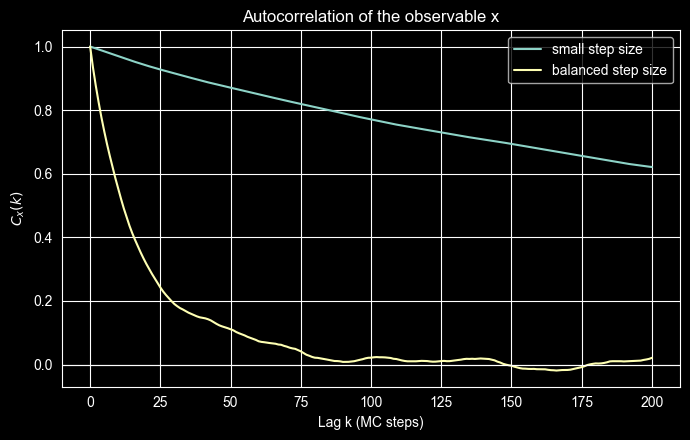

In [87]:
max_lag = 200

# Production regions
x_small_prod = x_small[burn_in:]
x_bal_prod = x_bal[burn_in:]

# TODO: calculate the two autocorrelation functions
C_small = autocorrelation(x_small_prod)
C_bal = autocorrelation(x_bal_prod)

lags = np.arange(max_lag + 1)

plt.figure(figsize=(7, 4.5))
plt.plot(lags, C_small, label="small step size")
plt.plot(lags, C_bal, label="balanced step size")
plt.axhline(0, linewidth=0.8)
plt.xlabel("Lag k (MC steps)")
plt.ylabel(r"$C_x(k)$")
plt.title("Autocorrelation of the observable x")
plt.legend()
plt.tight_layout()
plt.show()




The **potential-energy model** $U(x)$ defines the system's spatial energy landscape, which determines the canonical **target equilibrium distribution** $p_T(x) \propto \exp[-U(x)/k_BT]$ that dictates how probable each configuration is at a given temperature. The **sampling algorithm** (Metropolis chain) generates a stochastic sequence of configurations that explores this landscape using proposal and acceptance rules designed to satisfy detailed balance. Once the initial burn-in period is discarded to eliminate bias, the remaining **production samples** represent valid equilibrium states. Finally, these independent configurations are averaged to calculate the physical **observable average** $\langle A \rangle$, such as $\langle x^2 \rangle$ or basin occupation probabilities.

# Computational Scientist’s Guide to Monte Carlo Sampling & Diagnostics

---

## 1. Fundamental Conceptual Principles

### The Physical Goal: Ensemble Sampling vs. Energy Optimization

* **Sampling vs. Energy Minimization:** In physical systems at finite temperatures ($T > 0$), matter does not remain frozen at its lowest energy point (the global minimum). Instead, thermal energy ($k_BT$) drives constant fluctuations, allowing the system to explore surrounding higher-energy states.
* **The Target Distribution as Ground Truth:** At thermal equilibrium, a system's true state is described by a probability distribution (the canonical ensemble). The goal of Monte Carlo sampling is not to find a single "best" low-energy state, but to generate a representative sequence of configurations whose population statistics match the canonical Boltzmann distribution:



$$p_T(x) = \frac{1}{Z} \exp\left[-\frac{U(x)}{k_BT}\right]$$



---

### The Energy Landscape & The Barrier-Crossing Problem

* **Configuration Space:** The multi-dimensional spatial coordinate map representing all possible atomic/molecular arrangements the system can adopt.


* **Basins (Valleys):** Low-potential-energy regions where probability density peaks. The system naturally spends most of its time fluctuating within these regions.


* **Energy Barrier (The Peak):** High-energy regions separating stable basins.


* **The Exploration Bottleneck:** Moving between basins requires accepting temporary, energetically unfavorable ("uphill") moves. If proposed step sizes ($\Delta x$) are too timid or thermal energy ($k_BT$) is too low relative to barrier height ($\Delta U$), the system gets trapped inside a single basin, leading to incomplete sampling ("poor mixing").



---

### Detailed Balance & The Metropolis Criterion

* **Detailed Balance Condition:** To ensure a Markov chain converges to the exact target distribution $p_T(x)$, the probability flow between any two states $i$ and $j$ must balance in equilibrium:



$$\pi_i \cdot P_{i \to j} = \pi_j \cdot P_{j \to i}$$


* **Transition Breakdown:** The total transition probability $P_{i \to j}$ splits into a proposal rate $q_{i \to j}$ and an acceptance probability $a_{i \to j}$:



$$P_{i \to j} = q_{i \to j} \cdot a_{i \to j}$$


* **Symmetric Proposals:** Assuming symmetric trial moves ($q_{i \to j} = q_{j \to i}$), proposal terms cancel out, leaving the acceptance probability ratio matching the target Boltzmann ratio:



$$\frac{a_{j \to i}}{a_{i \to j}} = \frac{\pi_i}{\pi_j} = \frac{\exp(-U_i/k_BT)}{\exp(-U_j/k_BT)}$$


* **Metropolis Acceptance Rule:** Enforces this ratio cleanly using a minimum threshold:



$$a_{i \to j} = \min\left(1, \exp\left[-\frac{\Delta U}{k_BT}\right]\right)$$


* **Downhill Moves ($\Delta U \le 0$):** Always accepted ($a = 1.0$).


* **Uphill Moves ($\Delta U > 0$):** Accepted conditionally with probability $\exp(-\Delta U / k_BT)$.





---

### History Dependence, Autocorrelation, and Step Sizes

* **Markov Chain Memory:** Because each trial move originates from the previous configuration, consecutive steps are inherently correlated.


* **Autocorrelation Function $C(k)$:** Measures how strongly a measured property at step $n$ correlates with its value $k$ steps later:



$$C(k) = \frac{\langle (y_n - \mu)(y_{n+k} - \mu) \rangle}{\sigma^2}$$


* **Effective Sample Size:** Thousands of strongly correlated steps contain redundant information. True statistical precision is governed by the number of *independent* configurations sampled, which depends entirely on how fast $C(k)$ decays to zero (autocorrelation time).


* **The Step-Size Dilemma ($\Delta x$):**
* **Moves Too Small:** High acceptance rate ($>90\%$), but tiny spatial increments result in slow "crawling" (high autocorrelation) and basin trapping.


* **Moves Too Large:** Proposed steps frequently land high on steep energy walls, causing frequent rejections and freezing the system in place (high autocorrelation).


* **Balanced Moves:** Moderate acceptance rate ($20\% - 60\%$), allowing the chain to hop barriers efficiently and decorrelate rapidly.





---

## 2. Scientific Plot Diagnostics

```
                   SIMULATION WORKFLOW DIAGNOSTICS

  [ Initialization ] ---> [ Burn-In Phase ] ---> [ Production Phase ]
    Start at x0            Discard Data           Collect Samples
                                                      |
    +-------------------------------------------------+-------------------------------------------------+
    |                                                 |                                                 |
    v                                                 v                                                 v
Trajectory Plot                       Running Average Curve                             Histogram Overlay
Check for barrier hopping             Verify flat, stable asymptote                     Validate against theoretical pT(x)
& steady-state fluctuations           independent of additional steps                   across all basins and barriers

```

---

### A. Trajectory / Time-Series Plots ($x$ or $U$ vs. MC Step)

* **Equilibration (Burn-in Phase):** The initial transient region where the chain drifts monotonically away from an arbitrary starting coordinate $x_0$ toward the physical equilibrium zone. Data from this phase is unphysical and must be discarded.


* **Production Phase:** The steady-state region where observables oscillate around stable mean values.


* **Mixing & Barrier Hopping:** In a multi-well landscape (e.g., $U(x) = (x^2 - 1)^2$), a healthy trajectory displays frequent jumps across $x = 0$, spending equal time fluctuating around both minima ($x = -1$ and $x = +1$). A trajectory remaining flat near a single well for the entire run indicates trapping and invalid sampling.



---

### B. Convergence & Running Average Curves (Cumulative Observables vs. MC Step)

* **Purpose:** Evaluates whether a simulation has run long enough to yield time-independent statistical averages.


* **Indicator Function for Basin Population:**

$$P_N(x > 0) = \frac{1}{N} \sum_{n=1}^{N} I(x_n > 0), \quad \text{where } I(x_n) = \begin{cases} 1 & \text{if } x_n > 0 \\ 0 & \text{if } x_n \le 0 \end{cases}$$


* **Interpretation:**
* **Drifting/Jumping Line:** Indicates the chain is still in burn-in or lacks sufficient barrier crossings.


* **Flat Asymptote at $0.5$:** For a symmetric double well, a running average settling tightly at $0.5$ proves the system has sampled both wells equally and achieved thermodynamic equilibrium.





---

### C. Autocorrelation Decay Curves ($C(k)$ vs. Lag $k$)

* **Rapid Exponential Decay:** Indicates efficient sampling. The system decorrelates quickly, meaning samples separated by a small step gap $k$ are statistically independent.


* **Slow / High Decay:** Indicates inefficient sampling caused by step sizes that are either too small (slow spatial diffusion) or too large (mass rejections).



---

### D. Sampled Histogram vs. Target Distribution

* **The Ultimate Validation Check:** Overlays a density-normalized histogram (`density=True`) of production samples against the exact theoretical curve $p_T(x)$.


* **Matching Criteria:**
* **Peak Heights:** Bins near $x = \pm 1$ match the height of $p_T(x)$, confirming correct occupation of both energy wells.


* **Barrier Region:** Sample density near $x = 0$ matches the dip in $p_T(x)$, proving that uphill barrier crossings were sampled at the exact thermodynamic frequency dictated by detailed balance.





---

## 3. The 6-Point Checklist for Valid Monte Carlo Results

Before accepting any Monte Carlo data as scientifically valid, verify these six diagnostic checks:

1. **Target Distribution:** Ensure the proposal and acceptance rules enforce detailed balance for $p_T(x) \propto \exp[-U(x)/k_BT]$.


2. **Equilibration (Burn-in):** Verify that initial transient states have been discarded before calculating averages.


3. **Adequate Exploration (Mixing):** Confirm the trajectory traverses all relevant regions of configuration space without getting stuck in local energy wells.


4. **Convergence / Stable Averages:** Check that cumulative running averages flatten out and remain invariant as more steps are added.


5. **Reproducibility from Independent Starts:** Verify that independent runs initialized from different starting configurations ($x_0$) converge to identical final averages.


6. **Sensitivity to Proposal Size:** Ensure the results remain consistent across different reasonable trial step sizes ($\Delta x$).